### Get data

In [37]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import tensorflow as tf

In [38]:
26.4
6.4

# convergent lens

6.4

In [39]:
Q = 57.5

In [40]:
p0 = 33.7




In [41]:
# p = np.array([16.6, 21.1, 11.3, 5.4, 8.2, 18, 5, 8, 10.5, 11.2])
# q = np.array([31.4, 51.6, 16.3, 10.2, 12.7, 34.7, 56.4, 16.3, 15.1, 17.4])

In [42]:
p = np.array([5, 5.4,  8, 8.2, 10.5, 11.2, 11.3, 16.6, 18, 21])
q = np.array([10.2, 10.5, 15.5, 17, 19.5, 26.5, 25, 34.7, 43, 55])

x = [1/x for x in p]
y = [1/x for x in q]

In [43]:
p = [5, 5.4,  8, 8.2, 10.5, 11.2, 11.3, 16.6, 18, 21.1]
q = [10.2, 12.7, 15.1, 16.3, 16.3, 17.4, 31.4, 34.7, 51.6, 56.4]

x = [1/x for x in p]
y = [-1/x for x in q]

rem converging lens has positve q, diverging les has negative q  

In [44]:
x = np.array(x)
y = np.array(y)

In [45]:
sigma_x = np.full(10, 0.03)
sigma_y = np.full(10, 0.03)

### Fit

$\frac{1}{q} = -\frac{1}{p}+\frac{1}{f}$

y = -x + q  

only extimate q  


In [46]:
# Model with fixed slope m = -1: y = -x + q
def fit_model_fixed_slope(x, q):
    return -x + q

# Your data

# Fit only q (intercept = 1/f)
popt, pcov = curve_fit(fit_model_fixed_slope, x, y)
q_hat = popt[0]
sigma_q = np.sqrt(pcov[0, 0])

# Estimated focal length and dioptric power
f_est = 1 / q_hat
D_est = q_hat  # dioptric power in diopters

# Output
print(f"Estimated 1/f = {q_hat:.3f} ± {sigma_q:.3f} (1/m)")
print(f"Estimated focal length f = {f_est:.3f} m")
print(f"Estimated dioptric power D = {D_est:.3f} diopters")

Estimated 1/f = 0.055 ± 0.009 (1/m)
Estimated focal length f = 18.268 m
Estimated dioptric power D = 0.055 diopters


Estimated 1/f = 0.055 ± 0.009 (1/m)
Estimated focal length f = 18.268 m
Estimated dioptric power D = 0.055 diopters


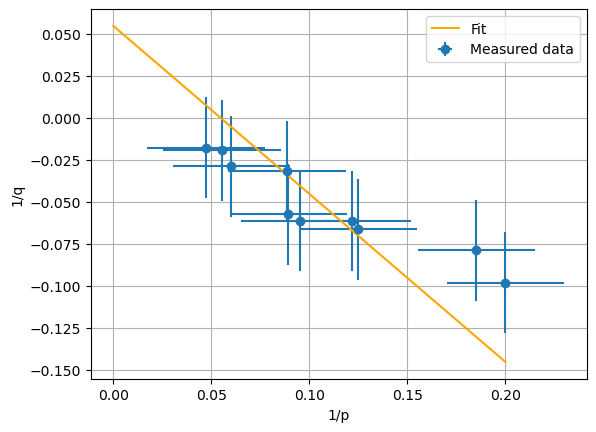

In [47]:

# Output
print(f"Estimated 1/f = {q_hat:.3f} ± {sigma_q:.3f} (1/m)")
print(f"Estimated focal length f = {f_est:.3f} m")
print(f"Estimated dioptric power D = {D_est:.3f} diopters")

# Optional: Plot
x_fit = np.linspace(0, max(x), 100)
y_fit = fit_model_fixed_slope(x_fit, *popt)

plt.errorbar(x, y, sigma_x, sigma_y, fmt='o', label='Measured data')
plt.plot(x_fit, y_fit, label='Fit', color='orange')

plt.xlabel('1/p')
plt.ylabel('1/q')
plt.grid(True)
plt.legend()
plt.show()


### Chi

In [48]:
import numpy as np
import tensorflow as tf
from scipy.optimize import curve_fit


# Convert x to TensorFlow tensor
x_tf = tf.convert_to_tensor(x, dtype=tf.float64)

# Compute the first fit (ignoring errors on x)
popt, pcov = curve_fit(fit_model_fixed_slope, x, y, sigma=sigma_y)

# Define a function to compute the derivative of the model
def compute_derivative(x_val, params):
    with tf.GradientTape() as tape:
        tape.watch(x_val)
        y_pred = fit_model_fixed_slope(x_val, *params)
    return tape.gradient(y_pred, x_val)  # Compute dy/dx

# Iteratively update errors and refit
for i in range(3):
    # Compute the propagated error using automatic differentiation
    df_dx = compute_derivative(x_tf, popt).numpy()  # Convert TF tensor to NumPy array
    sigma_eff = np.sqrt(sigma_y**2 + (df_dx * sigma_x)**2)  # Total effective error
    
    # Refit with updated sigma_eff
    popt, pcov = curve_fit(fit_model_fixed_slope, x, y, sigma=sigma_eff)
    
    # Compute chi-square
    chisq = np.sum(((y - fit_model_fixed_slope(x, *popt)) / sigma_eff) ** 2)
    
    # Print results
    print(f'Step {i + 1}...')
    print(f'Parameters: {popt}')
    print(f'Errors: {np.sqrt(np.diag(pcov))}')
    print(f'Chi-square: {chisq:.2f}')

Step 1...
Parameters: [0.05473946]
Errors: [0.0090891]
Chi-square: 4.13
Step 2...
Parameters: [0.05473946]
Errors: [0.0090891]
Chi-square: 4.13
Step 3...
Parameters: [0.05473946]
Errors: [0.0090891]
Chi-square: 4.13
